# Queen's GAMBIT — Train a GPT from scratch to play chess

Based on *Build a Large Language Model From Scratch* (Raschka), adapted for chess.

**Runtime → Change runtime type → T4 GPU** before running.

| Chapter | Role here |
|---|---|
| Ch02 | `ChessTokenizer` + `ChessDataset` (replaces tiktoken) |
| Ch03 | `MultiHeadAttention` |
| Ch04 | `GPTModel` |
| Ch05 | Training loop |
| Chess-specific | Legal move masking at inference |

## 0 — Install dependencies

In [ ]:
!pip install chess matplotlib tqdm zstandard -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 25.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## 1 — Write source files to disk

All module code is embedded here. Running this cell creates the `src/` package so the rest of the notebook can `import` normally.

In [ ]:
import os
os.makedirs('src', exist_ok=True)
os.makedirs('data', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)

# ── src/__init__.py ────────────────────────────────────────────────────
open('src/__init__.py', 'w').close()

# ── src/vocab.py ───────────────────────────────────────────────────────
with open('src/vocab.py', 'w') as f:
    f.write('''
import os

GAME_START = "<|game_start|>"
GAME_END   = "<|game_end|>"
SPECIAL_TOKENS = [GAME_START, GAME_END]


def _enumerate_all_moves():
    files = "abcdefgh"
    ranks = "12345678"
    pieces = "qrbn"
    moves = []
    for f1 in files:
        for r1 in ranks:
            for f2 in files:
                for r2 in ranks:
                    if f1 + r1 != f2 + r2:
                        moves.append(f1 + r1 + f2 + r2)
    for f1 in files:
        for f2 in files:
            for p in pieces:
                moves.append(f1 + "7" + f2 + "8" + p)
                moves.append(f1 + "2" + f2 + "1" + p)
    return moves


class ChessTokenizer:
    def __init__(self):
        all_moves = _enumerate_all_moves()
        vocab = SPECIAL_TOKENS + sorted(set(all_moves))
        self.move_to_id    = {m: i for i, m in enumerate(vocab)}
        self.id_to_move    = {i: m for m, i in self.move_to_id.items()}
        self.vocab_size    = len(vocab)
        self.game_start_id = self.move_to_id[GAME_START]
        self.game_end_id   = self.move_to_id[GAME_END]

    def encode(self, moves):
        return [self.move_to_id[m] for m in moves]

    def decode(self, ids):
        return [self.id_to_move[i] for i in ids]

    def save(self, path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        with open(path, "w") as f:
            for i in range(self.vocab_size):
                f.write(self.id_to_move[i] + "\\n")
        print(f"Vocab ({self.vocab_size} tokens) saved to {path}")

    @classmethod
    def load(cls, path):
        tok = cls.__new__(cls)
        with open(path) as f:
            vocab = [line.rstrip("\\n") for line in f]
        tok.move_to_id    = {m: i for i, m in enumerate(vocab)}
        tok.id_to_move    = {i: m for m, i in tok.move_to_id.items()}
        tok.vocab_size    = len(vocab)
        tok.game_start_id = tok.move_to_id[GAME_START]
        tok.game_end_id   = tok.move_to_id[GAME_END]
        return tok
''')

# ── src/dataset.py ─────────────────────────────────────────────────────
with open('src/dataset.py', 'w') as f:
    f.write('''
import torch
import chess.pgn
from torch.utils.data import Dataset, DataLoader
from src.vocab import ChessTokenizer


def parse_pgn(path, max_games=None, min_elo=0):
    from tqdm.auto import tqdm
    games, skipped = [], 0
    with open(path, encoding="utf-8", errors="ignore") as f:
        pbar = tqdm(unit="games", desc="Parsing PGN")
        while True:
            game = chess.pgn.read_game(f)
            if game is None:
                break
            if min_elo > 0:
                def _elo(v):
                    try: return int(v or 0)
                    except (ValueError, TypeError): return 0
                w = _elo(game.headers.get("WhiteElo", 0))
                b = _elo(game.headers.get("BlackElo", 0))
                if min(w, b) < min_elo:
                    skipped += 1
                    pbar.update()
                    pbar.set_postfix(kept=len(games), skipped=skipped)
                    continue
            moves = [m.uci() for m in game.mainline_moves()]
            if moves:
                games.append(moves)
            pbar.update()
            pbar.set_postfix(kept=len(games), skipped=skipped)
            if max_games and len(games) >= max_games:
                break
        pbar.close()
    print(f"Loaded {len(games)} games (skipped {skipped} below ELO {min_elo})")
    return games


def games_to_token_ids(games, tokenizer):
    stream = []
    for moves in games:
        stream.append(tokenizer.game_start_id)
        for m in moves:
            if m in tokenizer.move_to_id:
                stream.append(tokenizer.move_to_id[m])
        stream.append(tokenizer.game_end_id)
    return stream


class ChessDataset(Dataset):
    def __init__(self, token_ids, context_length, stride):
        self.input_ids, self.target_ids = [], []
        for i in range(0, len(token_ids) - context_length, stride):
            self.input_ids.append(torch.tensor(token_ids[i:i+context_length]))
            self.target_ids.append(torch.tensor(token_ids[i+1:i+context_length+1]))

    def __len__(self):  return len(self.input_ids)
    def __getitem__(self, idx):  return self.input_ids[idx], self.target_ids[idx]


def create_chess_dataloader(token_ids, context_length=256, stride=128,
                             batch_size=32, shuffle=True, drop_last=True, num_workers=2):
    dataset = ChessDataset(token_ids, context_length, stride)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      drop_last=drop_last, num_workers=num_workers, pin_memory=True)


def load_data(pgn_paths, tokenizer, max_games=None, min_elo=0):
    all_games = []
    for path in pgn_paths:
        all_games.extend(parse_pgn(path, max_games=max_games, min_elo=min_elo))
    return games_to_token_ids(all_games, tokenizer)
''')

# ── src/model.py ───────────────────────────────────────────────────────
with open('src/model.py', 'w') as f:
    f.write('''
import torch
import torch.nn as nn


class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query  = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key    = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value  = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout  = nn.Dropout(dropout)
        self.register_buffer("mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, n, d = x.shape
        k = self.W_key(x).view(b, n, self.num_heads, self.head_dim).transpose(1,2)
        q = self.W_query(x).view(b, n, self.num_heads, self.head_dim).transpose(1,2)
        v = self.W_value(x).view(b, n, self.num_heads, self.head_dim).transpose(1,2)
        scores = q @ k.transpose(2,3)
        scores.masked_fill_(self.mask.bool()[:n,:n], -torch.inf)
        w = self.dropout(torch.softmax(scores / k.shape[-1]**0.5, dim=-1))
        out = (w @ v).transpose(1,2).contiguous().view(b, n, self.d_out)
        return self.out_proj(out)


class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps   = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))
    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var  = x.var(dim=-1, keepdim=True, unbiased=False)
        return self.scale * (x - mean) / torch.sqrt(var + self.eps) + self.shift


class GELU(nn.Module):
    def forward(self, x):
        return 0.5*x*(1+torch.tanh(torch.sqrt(torch.tensor(2.0/torch.pi))*(x+0.044715*x**3)))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]),
            GELU(),
            nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"]),
        )
    def forward(self, x):  return self.layers(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(cfg["emb_dim"], cfg["emb_dim"],
                                       cfg["context_length"], cfg["drop_rate"],
                                       cfg["n_heads"], cfg["qkv_bias"])
        self.ff    = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop  = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        x = x + self.drop(self.att(self.norm1(x)))
        x = x + self.drop(self.ff(self.norm2(x)))
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb    = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb    = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb   = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head   = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, idx):
        b, t = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(t, device=idx.device))
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        return self.out_head(x)
''')

# ── src/generate.py ────────────────────────────────────────────────────
with open('src/generate.py', 'w') as f:
    f.write('''
import torch
import chess
from src.vocab import ChessTokenizer, GAME_START


def _legal_ids(board, tokenizer):
    return [tokenizer.move_to_id[m.uci()]
            for m in board.legal_moves if m.uci() in tokenizer.move_to_id]


def generate_move(model, board, context_ids, tokenizer, device, temperature=1.0):
    model.eval()
    ctx = model.pos_emb.weight.shape[0]
    idx = torch.tensor(context_ids[-ctx:], dtype=torch.long, device=device).unsqueeze(0)
    with torch.no_grad():
        logits = model(idx)[0, -1, :]
    legal = _legal_ids(board, tokenizer)
    if not legal:
        raise ValueError("No legal moves")
    mask = torch.full_like(logits, float("-inf"))
    mask[legal] = logits[legal]
    probs  = torch.softmax(mask / temperature, dim=-1)
    chosen = torch.multinomial(probs, num_samples=1).item()
    return tokenizer.id_to_move[chosen]


def generate_sample_game(model, tokenizer, device, num_moves=20, temperature=1.0):
    board   = chess.Board()
    ctx_ids = [tokenizer.game_start_id]
    moves   = []
    for _ in range(num_moves):
        if board.is_game_over():
            break
        try:
            uci = generate_move(model, board, ctx_ids, tokenizer, device, temperature)
        except ValueError:
            break
        board.push(chess.Move.from_uci(uci))
        ctx_ids.append(tokenizer.move_to_id[uci])
        moves.append(uci)
    return moves
''')

print('All source files written.')

All source files written.


## 2 — Config

In [ ]:
import torch
from src.vocab import ChessTokenizer

tokenizer = ChessTokenizer()
print(f'Vocab size: {tokenizer.vocab_size}')
tokenizer.save('data/vocab.txt')

CHESS_GPT_CONFIG = {
    'vocab_size':     tokenizer.vocab_size,  # 4546
    'context_length': 256,
    'emb_dim':        256,
    'n_heads':        8,
    'n_layers':       6,
    'drop_rate':      0.1,
    'qkv_bias':       False,
}

TRAIN_SETTINGS = {
    'learning_rate': 3e-4,
    'weight_decay':  0.1,
    'num_epochs':    10,
    'batch_size':    64,
    'eval_freq':     200,
    'eval_iter':     10,
    'min_elo':       0,   # all games
    'max_games':     None,  # None = use all games that pass ELO filter
}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Vocab size: 4546
Vocab (4546 tokens) saved to data/vocab.txt
Device: cuda


## 3 — Download Lichess data

Jan 2013 dump: ~40 MB compressed, ~400 MB uncompressed, ~120k games (after 1800+ ELO filter ~20-30k).

For more data, browse https://database.lichess.org/ and change the URL below.

In [ ]:
import os, zstandard, requests

PGN_PATH = 'data/lichess.pgn'
URL = 'https://database.lichess.org/standard/lichess_db_standard_rated_2013-01.pgn.zst'

def download_lichess(url, pgn_path):
    zst_path = pgn_path + '.zst'
    print(f'Fetching {url} ...')
    headers = {'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36'}
    r = requests.get(url, headers=headers, stream=True, timeout=600)
    print(f'HTTP {r.status_code}  Content-Length: {r.headers.get("Content-Length", "unknown")}')
    if r.status_code != 200:
        raise RuntimeError(f'HTTP {r.status_code}')
    total, received = int(r.headers.get('Content-Length', 0)), 0
    with open(zst_path, 'wb') as f:
        for chunk in r.iter_content(chunk_size=1 << 20):
            f.write(chunk)
            received += len(chunk)
            if total:
                print(f'  {received/1e6:.0f} / {total/1e6:.0f} MB', end='\r')
    print(f'\nDecompressing...')
    dctx = zstandard.ZstdDecompressor()
    with open(zst_path, 'rb') as src, open(pgn_path, 'wb') as dst:
        dctx.copy_stream(src, dst)
    os.remove(zst_path)
    print(f'PGN ready: {os.path.getsize(pgn_path)/1e6:.0f} MB')

if not os.path.exists(PGN_PATH):
    download_lichess(URL, PGN_PATH)
else:
    print(f'Already exists: {os.path.getsize(PGN_PATH)/1e6:.0f} MB')


Fetching https://database.lichess.org/standard/lichess_db_standard_rated_2013-01.pgn.zst ...
HTTP 200  Content-Length: 17761302
  18 / 18 MB
Decompressing...
PGN ready: 93 MB


## 4 — Load + tokenize games

In [ ]:
from src.dataset import load_data, create_chess_dataloader

all_ids = load_data(
    [PGN_PATH], tokenizer,
    max_games=TRAIN_SETTINGS['max_games'],
    min_elo=TRAIN_SETTINGS['min_elo'],
)

split     = int(0.9 * len(all_ids))
train_ids = all_ids[:split]
val_ids   = all_ids[split:]
print(f'Train tokens: {len(train_ids):,}  |  Val tokens: {len(val_ids):,}')

ctx = CHESS_GPT_CONFIG['context_length']
bs  = TRAIN_SETTINGS['batch_size']

train_loader = create_chess_dataloader(train_ids, context_length=ctx, stride=ctx,
                                        batch_size=bs, shuffle=True,  drop_last=True)
val_loader   = create_chess_dataloader(val_ids,   context_length=ctx, stride=ctx,
                                        batch_size=bs, shuffle=False, drop_last=False)
print(f'Train batches: {len(train_loader)}  |  Val batches: {len(val_loader)}')

Parsing PGN: 0games [00:00, ?games/s]

Loaded 121332 games (skipped 0 below ELO 0)
Train tokens: 7,558,065  |  Val tokens: 839,786
Train batches: 461  |  Val batches: 52


## 5 — Build model

In [ ]:
from src.model import GPTModel

torch.manual_seed(42)
model = GPTModel(CHESS_GPT_CONFIG).to(device)

total = sum(p.numel() for p in model.parameters())
print(f'Parameters: {total:,}')

# Sanity check
dummy = torch.randint(0, CHESS_GPT_CONFIG['vocab_size'], (2, 32)).to(device)
print(f'Forward pass: {dummy.shape} -> {model(dummy).shape}  OK')

Parameters: 7,127,552
Forward pass: torch.Size([2, 32]) -> torch.Size([2, 32, 4546])  OK


## 6 — Train

In [ ]:
import torch.nn as nn
import matplotlib.pyplot as plt
from src.generate import generate_sample_game


def calc_loss_batch(x, y, model, device):
    logits = model(x.to(device))
    return nn.functional.cross_entropy(logits.flatten(0,1), y.to(device).flatten())


def calc_loss_loader(loader, model, device, num_batches=None):
    total, n = 0.0, 0
    nb = min(num_batches or len(loader), len(loader))
    for i, (x, y) in enumerate(loader):
        if i >= nb: break
        total += calc_loss_batch(x, y, model, device).item()
        n += 1
    return total / n if n else float('nan')


def train(model, train_loader, val_loader, optimizer, device,
          num_epochs, eval_freq, eval_iter, tokenizer):
    train_losses, val_losses, tokens_seen_list = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(x, y, model, device)
            loss.backward()
            optimizer.step()
            tokens_seen += x.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                model.eval()
                with torch.no_grad():
                    tl = calc_loss_loader(train_loader, model, device, eval_iter)
                    vl = calc_loss_loader(val_loader,   model, device, eval_iter)
                model.train()
                train_losses.append(tl)
                val_losses.append(vl)
                tokens_seen_list.append(tokens_seen)
                print(f'Ep {epoch+1} (Step {global_step:06d}): '
                      f'Train {tl:.3f}  Val {vl:.3f}')

        sample = generate_sample_game(model, tokenizer, device, num_moves=10)
        print(f'  Sample: {" ".join(sample)}')

        ckpt = f'checkpoints/chess_gpt_ep{epoch+1}.pth'
        torch.save(model.state_dict(), ckpt)
        print(f'  Saved: {ckpt}')

    return train_losses, val_losses, tokens_seen_list


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=TRAIN_SETTINGS['learning_rate'],
    weight_decay=TRAIN_SETTINGS['weight_decay'],
)

train_losses, val_losses, tokens_seen = train(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=TRAIN_SETTINGS['num_epochs'],
    eval_freq=TRAIN_SETTINGS['eval_freq'],
    eval_iter=TRAIN_SETTINGS['eval_iter'],
    tokenizer=tokenizer,
)

Ep 1 (Step 000000): Train 8.486  Val 8.486
Ep 1 (Step 000200): Train 5.739  Val 5.722
Ep 1 (Step 000400): Train 5.332  Val 5.335
  Sample: f2f4 d7d5 b2b3 f7f5 d2d3 b8d7 g2g3 d5d4 c1d2 g8f6
  Saved: checkpoints/chess_gpt_ep1.pth
Ep 2 (Step 000600): Train 4.980  Val 4.979
Ep 2 (Step 000800): Train 4.711  Val 4.715
  Sample: c2c4 g7g6 b1c3 d7d5 c4d5 d8d5 b2b4 f8g7 c1b2 c7c6
  Saved: checkpoints/chess_gpt_ep2.pth
Ep 3 (Step 001000): Train 4.501  Val 4.492
Ep 3 (Step 001200): Train 4.261  Val 4.273
  Sample: b1c3 d7d5 e2e3 e7e6 f1d3 g8f6 b2b4 c7c6 c1b2 f8b4
  Saved: checkpoints/chess_gpt_ep3.pth
Ep 4 (Step 001400): Train 4.072  Val 4.096
Ep 4 (Step 001600): Train 3.917  Val 3.949
Ep 4 (Step 001800): Train 3.781  Val 3.822
  Sample: g1f3 g8f6 g2g3 g7g6 f1g2 f8g7 e1g1 c7c6 f1e1 e8g8
  Saved: checkpoints/chess_gpt_ep4.pth
Ep 5 (Step 002000): Train 3.687  Val 3.722
Ep 5 (Step 002200): Train 3.588  Val 3.645
  Sample: e2e4 e7e5 g1f3 b8c6 b1c3 g8f6 d2d4 d7d6 d4e5 d6e5
  Saved: checkpoints/chess_g

## 7 — Plot losses

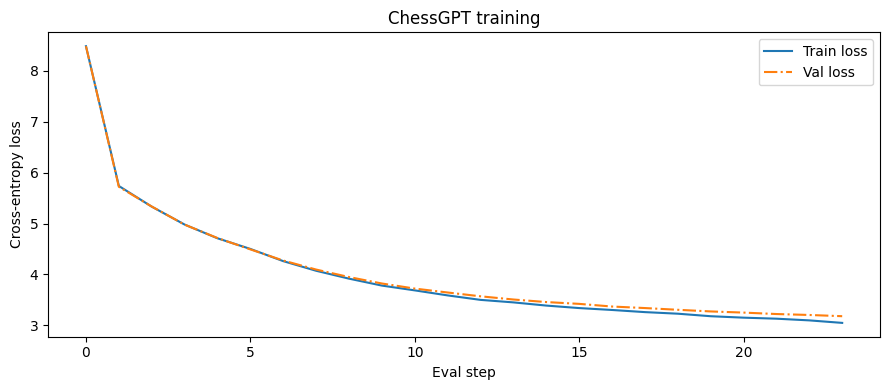

Final train loss: 3.048  |  val loss: 3.180


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
steps = list(range(len(train_losses)))
ax.plot(steps, train_losses, label='Train loss')
ax.plot(steps, val_losses, linestyle='-.', label='Val loss')
ax.set_xlabel('Eval step')
ax.set_ylabel('Cross-entropy loss')
ax.set_title('Queen's GAMBIT training')
ax.legend()
plt.tight_layout()
plt.savefig('loss.png', dpi=150)
plt.show()
print(f'Final train loss: {train_losses[-1]:.3f}  |  val loss: {val_losses[-1]:.3f}')

## 8 — Watch the model play against itself

In [ ]:
import chess
from src.generate import generate_move

model.eval()

board       = chess.Board()
context_ids = [tokenizer.game_start_id]
move_num    = 1

for _ in range(400):  # safety ceiling; board.is_game_over() stops at real endings
    if board.is_game_over():
        break
    is_white = board.turn == chess.WHITE
    uci  = generate_move(model, board, context_ids, tokenizer, device, temperature=0.8)
    move = chess.Move.from_uci(uci)
    san  = board.san(move)
    board.push(move)
    context_ids.append(tokenizer.move_to_id[uci])
    if is_white:
        print(f'{move_num:3}. {san}', end='')
    else:
        print(f'  {san}')
        move_num += 1

print(f'\nResult: {board.result()}')
if board.is_checkmate():
    print('CHECKMATE')
elif board.is_stalemate():
    print('STALEMATE')
elif board.is_repetition():
    print('DRAW - repetition')
elif board.is_fifty_moves():
    print('DRAW - 50 move rule')
print(board)

## 9 — Save checkpoint to Google Drive (optional)

In [ ]:
# Uncomment to mount Drive and copy the final checkpoint

# from google.colab import drive
# drive.mount('/content/drive')
# !cp checkpoints/chess_gpt_ep10.pth /content/drive/MyDrive/chess_gpt_ep10.pth
# print('Saved to Drive.')